Dataset exists: True
Dataset loaded successfully!
Dataset shape: (2075259, 9)

FIRST FIVE RECORDS
         Date      Time  Global_active_power  Global_reactive_power  Voltage  \
0  16/12/2006  17:24:00                4.216                  0.418   234.84   
1  16/12/2006  17:25:00                5.360                  0.436   233.63   
2  16/12/2006  17:26:00                5.374                  0.498   233.29   
3  16/12/2006  17:27:00                5.388                  0.502   233.74   
4  16/12/2006  17:28:00                3.666                  0.528   235.68   

   Global_intensity  Sub_metering_1  Sub_metering_2  Sub_metering_3  
0              18.4             0.0             1.0            17.0  
1              23.0             0.0             1.0            16.0  
2              23.0             0.0             2.0            17.0  
3              23.0             0.0             1.0            17.0  
4              15.8             0.0             1.0            17.0  



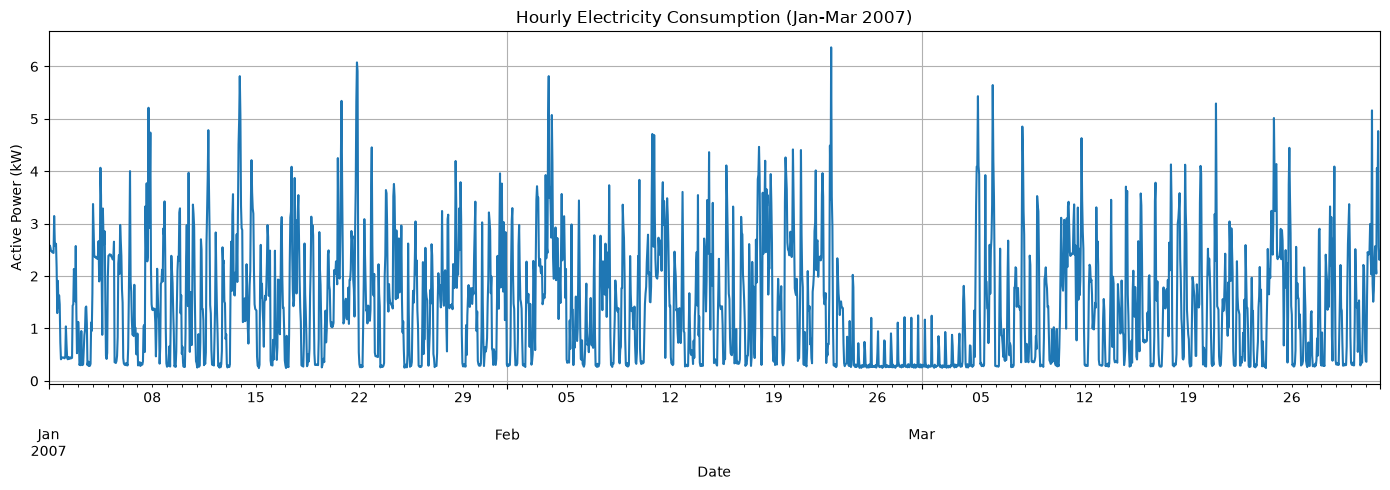

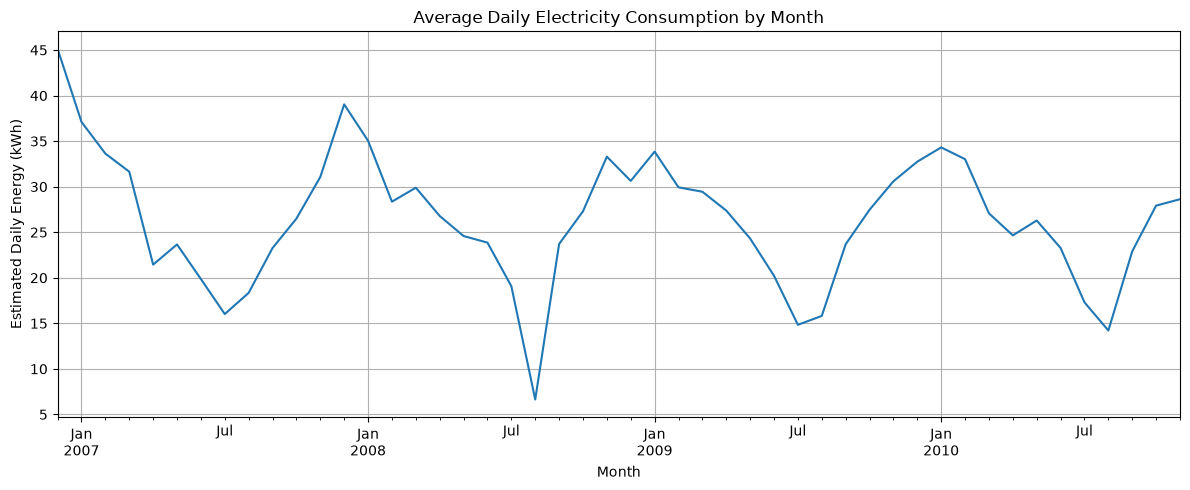

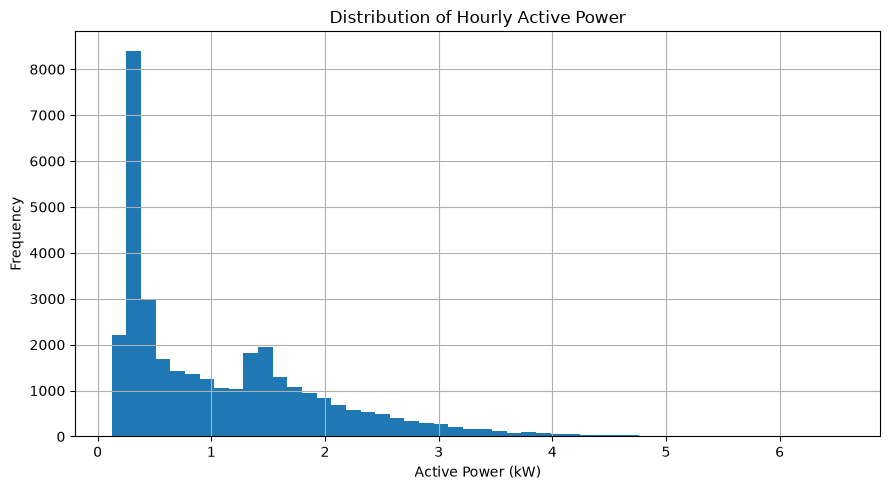

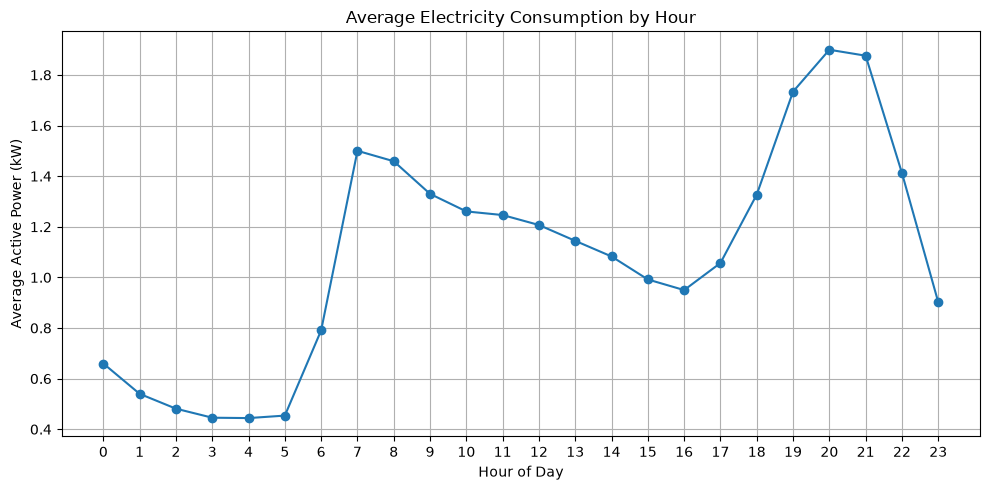


REGRESSION COMPARISON
Linear Regression MAE: 5.913
Polynomial Regression MAE: 9.61


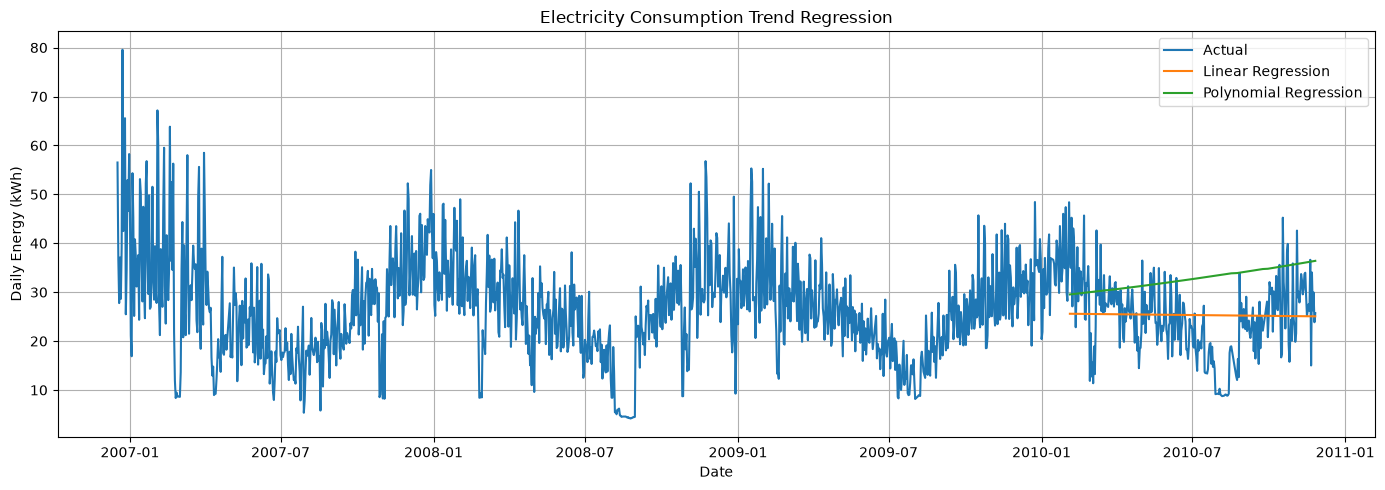


AUGMENTED DICKEY-FULLER TEST
ADF Statistic: -2.2727
p-value: 0.180928
Result: Evidence of non-stationarity.


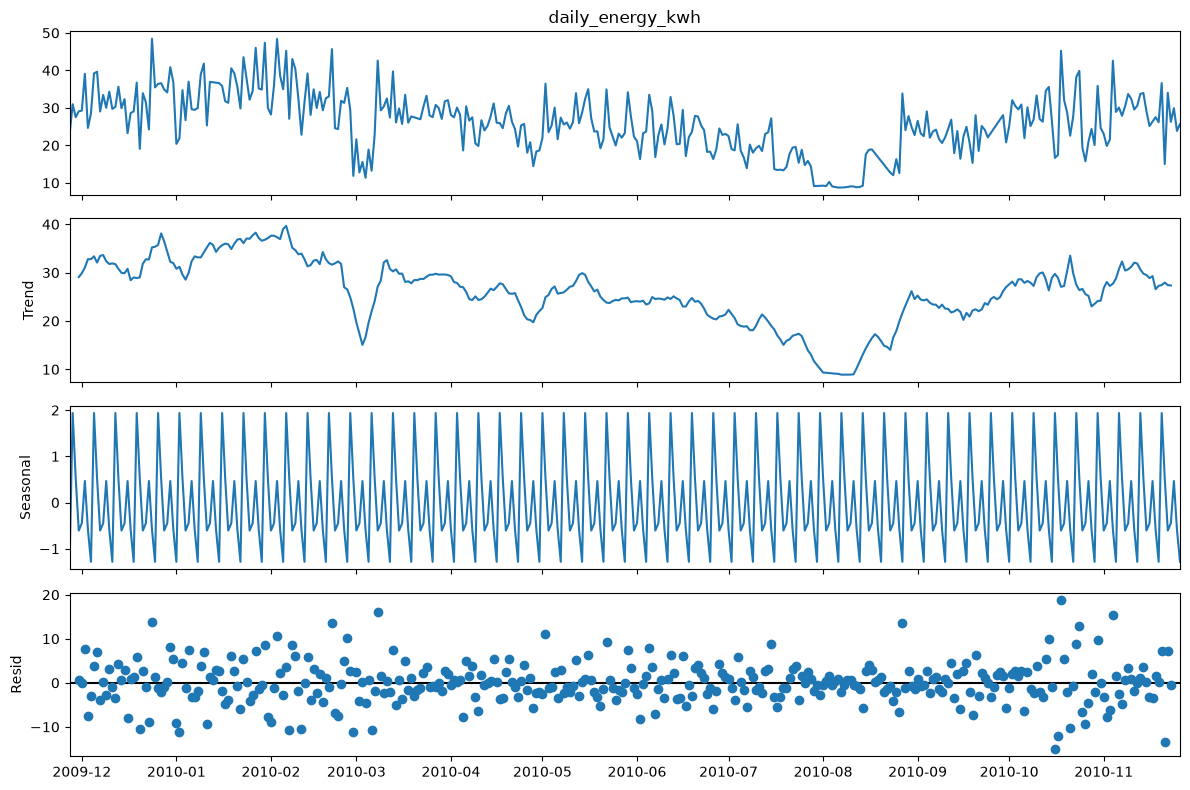

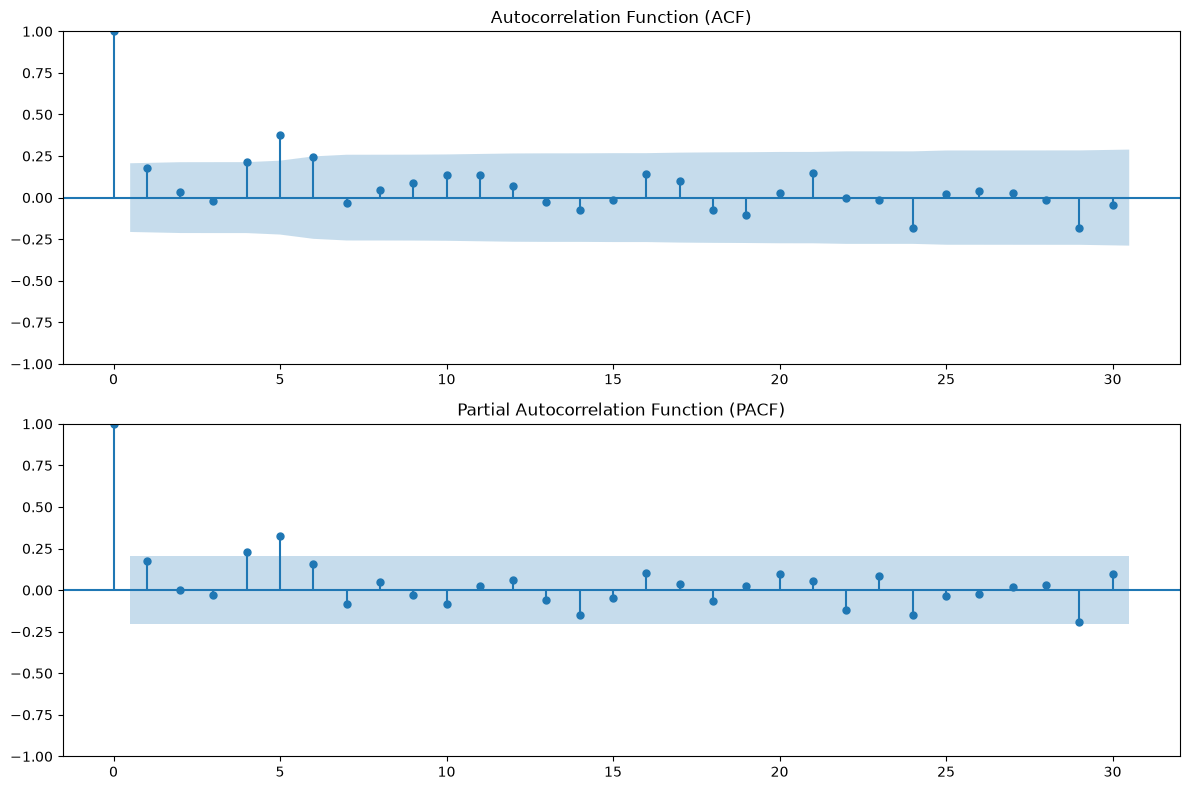


TRAINING RECORDS: 1411
TESTING RECORDS: 30

FORECAST ACCURACY COMPARISON
                MAE   RMSE  MAPE (%)
Holt-Winters  5.757  7.071    19.659
ARIMA(2,1,2)  4.724  6.065    16.854


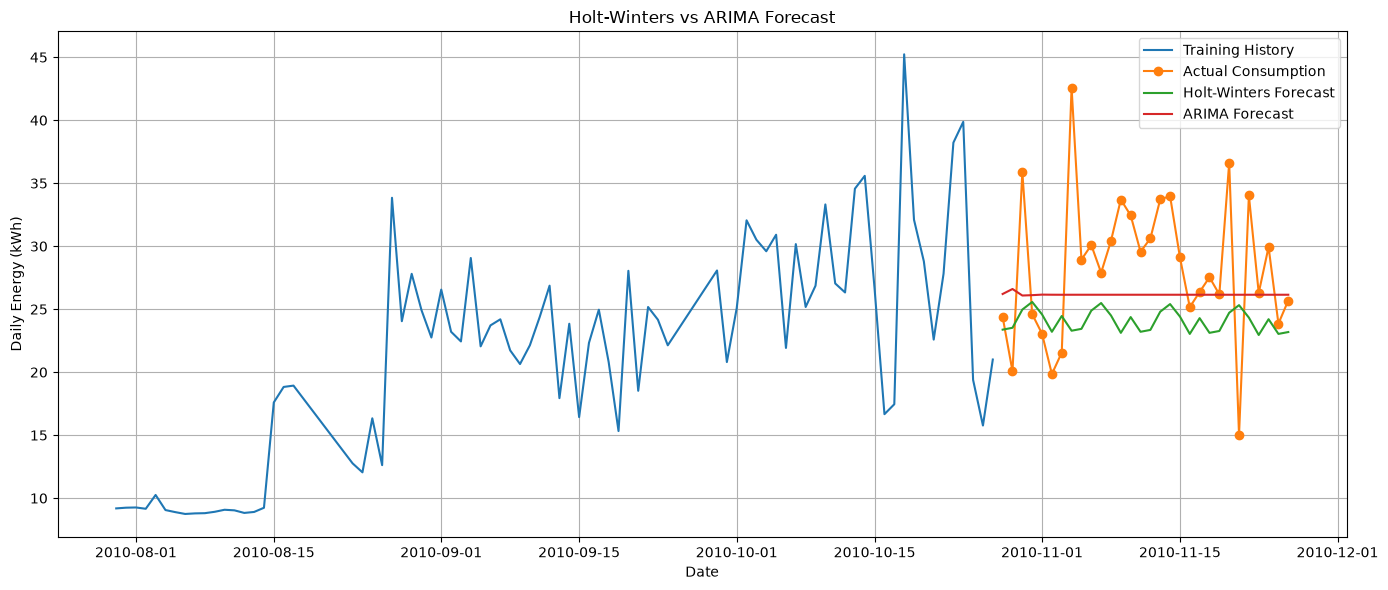


BEST MODEL: ARIMA(2,1,2)

NEXT 30 DAYS FORECAST
            forecast_daily_energy_kwh
2010-11-27                      27.78
2010-11-28                      27.49
2010-11-29                      27.35
2010-11-30                      27.39
2010-12-01                      27.40
2010-12-02                      27.39
2010-12-03                      27.39
2010-12-04                      27.39
2010-12-05                      27.39
2010-12-06                      27.39
2010-12-07                      27.39
2010-12-08                      27.39
2010-12-09                      27.39
2010-12-10                      27.39
2010-12-11                      27.39
2010-12-12                      27.39
2010-12-13                      27.39
2010-12-14                      27.39
2010-12-15                      27.39
2010-12-16                      27.39
2010-12-17                      27.39
2010-12-18                      27.39
2010-12-19                      27.39
2010-12-20                      27.39
2

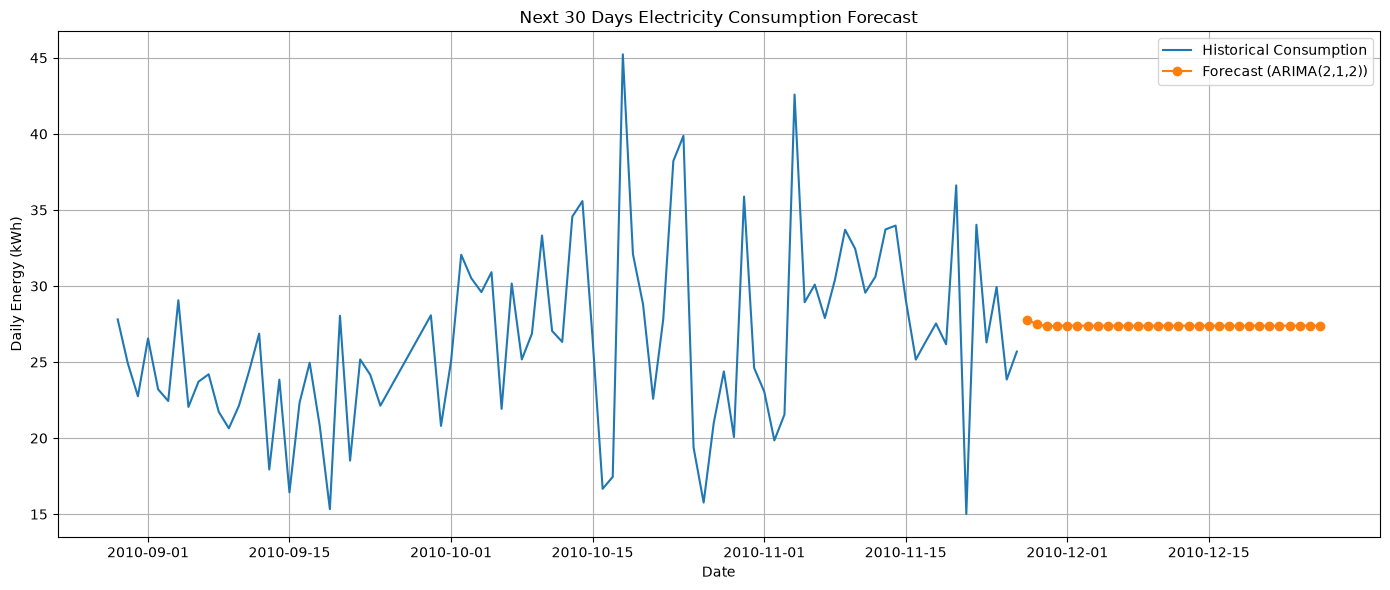


PROJECT COMPLETED SUCCESSFULLY
Saved files:
1. data/cleaned_hourly_electricity.csv
2. data/forecast_model_comparison.csv
3. data/next_30_day_forecast.csv


In [3]:

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import zipfile
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

data_dir = Path(r"C:\Users\ACER\OneDrive\Desktop\a")

data_path = data_dir / "household_power_consumption.txt"

print("Dataset exists:", data_path.exists())

df = pd.read_csv(
    data_path,
    sep=";",
    na_values=["?", ""],
    low_memory=False
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)




print("\nFIRST FIVE RECORDS")
print(df.head())

print("\nDATASET SHAPE")
print(df.shape)

print("\nDATASET INFORMATION")
df.info()


# 3. DATA CLEANING

df["datetime"] = pd.to_datetime(
    df["Date"].astype(str) + " " + df["Time"].astype(str),
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

df = df.dropna(subset=["datetime"])

numeric_cols = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.set_index("datetime").sort_index()

print("\nMISSING VALUES BEFORE CLEANING")
print(df[numeric_cols].isna().sum())


# 4. RESAMPLE TO HOURLY DATA

hourly = df[numeric_cols].resample("h").mean()

hourly = hourly.interpolate(
    method="time",
    limit=6,
    limit_area="inside"
)

hourly = hourly.dropna(
    subset=["Global_active_power"]
)

hourly = hourly[
    hourly["Global_active_power"] >= 0
].copy()

print("\nHOURLY DATASET SHAPE")
print(hourly.shape)

print("\nMISSING VALUES AFTER CLEANING")
print(hourly[numeric_cols].isna().sum())


# 5. OUTLIER DETECTION USING IQR

q1 = hourly["Global_active_power"].quantile(0.25)
q3 = hourly["Global_active_power"].quantile(0.75)

iqr = q3 - q1

lower_bound = max(0, q1 - 1.5 * iqr)
upper_bound = q3 + 1.5 * iqr

hourly["is_outlier"] = (
    (hourly["Global_active_power"] < lower_bound) |
    (hourly["Global_active_power"] > upper_bound)
)

print("\nOUTLIER ANALYSIS")
print("Lower bound:", round(lower_bound, 3))
print("Upper bound:", round(upper_bound, 3))
print("Number of outliers:", int(hourly["is_outlier"].sum()))


# 6. SAVE CLEANED DATASET

hourly.to_csv(
    data_dir / "cleaned_hourly_electricity.csv"
)

print("\nCleaned dataset saved.")


# 7. DESCRIPTIVE STATISTICS

power = hourly["Global_active_power"].dropna()

print("\nDESCRIPTIVE STATISTICS")
print(power.describe())

print("\nMedian:", round(power.median(), 3))
print("Variance:", round(power.var(), 3))
print("Standard deviation:", round(power.std(), 3))
print("Skewness:", round(power.skew(), 3))
print("Kurtosis:", round(power.kurtosis(), 3))


# 8. DAILY ENERGY ESTIMATION

daily_energy = power.resample("D").sum(min_count=18).dropna()

daily_energy.name = "daily_energy_kwh"

print("\nDAILY ENERGY STATISTICS")
print(daily_energy.describe())


# 9. HOURLY ELECTRICITY CONSUMPTION GRAPH

plt.figure(figsize=(14, 5))

power.loc["2007-01":"2007-03"].plot()

plt.title("Hourly Electricity Consumption (Jan-Mar 2007)")
plt.xlabel("Date")
plt.ylabel("Active Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()


# 10. MONTHLY CONSUMPTION TREND

monthly_energy = daily_energy.resample("MS").mean()

plt.figure(figsize=(12, 5))

monthly_energy.plot()

plt.title("Average Daily Electricity Consumption by Month")
plt.xlabel("Month")
plt.ylabel("Estimated Daily Energy (kWh)")
plt.grid(True)
plt.tight_layout()
plt.show()


# 11. DISTRIBUTION OF ELECTRICITY CONSUMPTION

plt.figure(figsize=(9, 5))

power.hist(bins=50)

plt.title("Distribution of Hourly Active Power")
plt.xlabel("Active Power (kW)")
plt.ylabel("Frequency")
plt.grid(True)
plt.tight_layout()
plt.show()


# 12. HOURLY CONSUMPTION PATTERN

hour_profile = hourly.groupby(
    hourly.index.hour
)["Global_active_power"].mean()

plt.figure(figsize=(10, 5))

hour_profile.plot(marker="o")

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Active Power (kW)")
plt.xticks(range(24))
plt.grid(True)
plt.tight_layout()
plt.show()


# 13. LINEAR AND POLYNOMIAL REGRESSION

reg_data = daily_energy.to_frame().dropna().copy()

reg_data["time_index"] = np.arange(len(reg_data))
reg_data["time_squared"] = reg_data["time_index"] ** 2

split = int(len(reg_data) * 0.8)

train_reg = reg_data.iloc[:split]
test_reg = reg_data.iloc[split:]

linear_model = LinearRegression()

linear_model.fit(
    train_reg[["time_index"]],
    train_reg["daily_energy_kwh"]
)

linear_predictions = linear_model.predict(
    test_reg[["time_index"]]
)

polynomial_model = LinearRegression()

polynomial_model.fit(
    train_reg[["time_index", "time_squared"]],
    train_reg["daily_energy_kwh"]
)

polynomial_predictions = polynomial_model.predict(
    test_reg[["time_index", "time_squared"]]
)

print("\nREGRESSION COMPARISON")

print(
    "Linear Regression MAE:",
    round(
        mean_absolute_error(
            test_reg["daily_energy_kwh"],
            linear_predictions
        ), 3
    )
)

print(
    "Polynomial Regression MAE:",
    round(
        mean_absolute_error(
            test_reg["daily_energy_kwh"],
            polynomial_predictions
        ), 3
    )
)

plt.figure(figsize=(14, 5))

plt.plot(
    reg_data.index,
    reg_data["daily_energy_kwh"],
    label="Actual"
)

plt.plot(
    test_reg.index,
    linear_predictions,
    label="Linear Regression"
)

plt.plot(
    test_reg.index,
    polynomial_predictions,
    label="Polynomial Regression"
)

plt.title("Electricity Consumption Trend Regression")
plt.xlabel("Date")
plt.ylabel("Daily Energy (kWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 14. STATIONARITY TEST USING ADF

series = daily_energy.asfreq("D").interpolate(
    method="time",
    limit_area="inside"
).dropna()

diagnostic_series = series.iloc[-90:]

adf_result = adfuller(
    diagnostic_series,
    autolag="AIC"
)

print("\nAUGMENTED DICKEY-FULLER TEST")

print("ADF Statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 6))

if adf_result[1] < 0.05:
    print("Result: Evidence of stationarity.")
else:
    print("Result: Evidence of non-stationarity.")


# 15. TREND AND SEASONALITY DECOMPOSITION

decomposition_data = series.iloc[-365:]

decomposition = seasonal_decompose(
    decomposition_data,
    model="additive",
    period=7
)

decomposition.plot()

plt.gcf().set_size_inches(12, 8)
plt.tight_layout()
plt.show()


# 16. ACF AND PACF ANALYSIS

fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 8)
)

plot_acf(
    diagnostic_series,
    lags=30,
    ax=axes[0]
)

plot_pacf(
    diagnostic_series,
    lags=30,
    method="ywm",
    ax=axes[1]
)

axes[0].set_title("Autocorrelation Function (ACF)")
axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()


# 17. TRAIN-TEST SPLIT FOR FORECASTING

test_days = 30

train = series.iloc[:-test_days]
test = series.iloc[-test_days:]

print("\nTRAINING RECORDS:", len(train))
print("TESTING RECORDS:", len(test))


# 18. HOLT-WINTERS FORECASTING

hw_model = ExponentialSmoothing(
    train,
    trend="add",
    seasonal="add",
    seasonal_periods=7,
    initialization_method="estimated"
).fit(optimized=True)

hw_forecast = hw_model.forecast(test_days)

hw_forecast.index = test.index


# 19. ARIMA FORECASTING

arima_model = ARIMA(
    train,
    order=(2, 1, 2)
).fit()

arima_forecast = arima_model.forecast(
    steps=test_days
)

arima_forecast.index = test.index


# 20. FORECAST ACCURACY

def calculate_metrics(actual, predicted):

    actual = np.asarray(actual)
    predicted = np.asarray(predicted)

    mae = mean_absolute_error(
        actual,
        predicted
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    nonzero = actual != 0

    mape = np.mean(
        np.abs(
            (actual[nonzero] - predicted[nonzero])
            / actual[nonzero]
        )
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }


results = pd.DataFrame({
    "Holt-Winters": calculate_metrics(
        test,
        hw_forecast
    ),
    "ARIMA(2,1,2)": calculate_metrics(
        test,
        arima_forecast
    )
}).T

print("\nFORECAST ACCURACY COMPARISON")
print(results.round(3))


# 21. PLOT FORECAST COMPARISON

plt.figure(figsize=(14, 6))

plt.plot(
    train.index[-90:],
    train.iloc[-90:],
    label="Training History"
)

plt.plot(
    test.index,
    test,
    label="Actual Consumption",
    marker="o"
)

plt.plot(
    hw_forecast.index,
    hw_forecast,
    label="Holt-Winters Forecast"
)

plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast"
)

plt.title("Holt-Winters vs ARIMA Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Energy (kWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 22. SELECT BEST MODEL USING TEST RMSE

best_model_name = results["RMSE"].idxmin()

print("\nBEST MODEL:", best_model_name)


# 23. FORECAST NEXT 30 DAYS

if best_model_name == "Holt-Winters":

    final_model = ExponentialSmoothing(
        series,
        trend="add",
        seasonal="add",
        seasonal_periods=7,
        initialization_method="estimated"
    ).fit(optimized=True)

    future_forecast = final_model.forecast(30)

else:

    final_model = ARIMA(
        series,
        order=(2, 1, 2)
    ).fit()

    future_forecast = final_model.forecast(
        steps=30
    )


# 24. DISPLAY FUTURE FORECAST

future_df = pd.DataFrame({
    "forecast_daily_energy_kwh": future_forecast
})

print("\nNEXT 30 DAYS FORECAST")
print(future_df.round(2))


# 25. PLOT FUTURE FORECAST

plt.figure(figsize=(14, 6))

plt.plot(
    series.index[-90:],
    series.iloc[-90:],
    label="Historical Consumption"
)

plt.plot(
    future_forecast.index,
    future_forecast,
    label=f"Forecast ({best_model_name})",
    marker="o"
)

plt.title("Next 30 Days Electricity Consumption Forecast")
plt.xlabel("Date")
plt.ylabel("Daily Energy (kWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# 26. SAVE RESULTS

hourly.to_csv(
    data_dir / "cleaned_hourly_electricity.csv"
)

results.to_csv(
    data_dir / "forecast_model_comparison.csv"
)

future_df.to_csv(
    data_dir / "next_30_day_forecast.csv"
)

print("\nPROJECT COMPLETED SUCCESSFULLY")

print("Saved files:")
print("1. data/cleaned_hourly_electricity.csv")
print("2. data/forecast_model_comparison.csv")
print("3. data/next_30_day_forecast.csv")

